#### Covariance and Pearson Correlation Coefficient
### Quick Overview
- **Covariance** tracks the direction of joint linear movement between two variables (whether they increase together or move in opposite directions).
- **Pearson Correlation ($r$)** rescales covariance to a standardized range between $-1$ and $+1$, quantifying both direction and strength independent of measurement units.
- **Linearity Assumption:** Both metrics strictly evaluate linear relationships and can fail to capture strong non-linear patterns (such as curves or quadratic dependencies).

#### Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# Apply clean visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100

## 1. Sample Covariance (`np.cov`)

* **What it does:** Measures how much two variables change together. A positive value means they move in the same direction; a negative value means they move in opposite directions.
* **Mathematical Notation:**
  $$s_{xy} = \operatorname{Cov}(X, Y) = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$
  *Where:*
  * $s_{xy}$ (*s sub x y*): Unbiased sample covariance
  * $\bar{x}$ (*x-bar*): Mean of variable $X$
  * $\bar{y}$ (*y-bar*): Mean of variable $Y$
  * $n$ (*n*): Number of observations ($n - 1$ adjusts for sample degrees of freedom)
* **Naive Example:** Study hours $X = [2, 4, 6]$ and Exam Scores $Y = [50, 70, 90]$ ($n = 3$).
  * $\bar{x} = 4$, $\bar{y} = 70$
  * Deviations $X$: $[-2, 0, 2]$, Deviations $Y$: $[-20, 0, 20]$
  * Sum of products: $(-2 \times -20) + (0 \times 0) + (2 \times 20) = 40 + 0 + 40 = 80$
  * Covariance: $\frac{80}{3 - 1} = 40.0$
* **When to use:** When calculating joint variability, portfolio risk matrices, or preparing features for Principal Component Analysis (PCA).

### Sample Covariance: Step-by-Step Numerical Example

Covariance aggregates the multiplied deviations of two variables from their respective means to see if positive deviations in $X$ pair with positive deviations in $Y$.

---

### Step-by-Step Example

#### 1. Input Datasets
$$\text{Study Hours } (X): [2, 4, 6] \quad (n = 3)$$
$$\text{Exam Scores } (Y): [50, 70, 90] \quad (n = 3)$$

#### 2. Calculate Means
$$\bar{x} = \frac{2 + 4 + 6}{3} = 4$$
$$\bar{y} = \frac{50 + 70 + 90}{3} = 70$$

#### 3. Compute Deviations and Product of Deviations
| Student | $x_i$ | $y_i$ | $(x_i - \bar{x})$ | $(y_i - \bar{y})$ | Product $(x_i - \bar{x})(y_i - \bar{y})$ |
|---|---|---|---|---|---|
| 1 | 2 | 50 | $2 - 4 = -2$ | $50 - 70 = -20$ | $(-2) \times (-20) = 40$ |
| 2 | 4 | 70 | $4 - 4 = 0$ | $70 - 70 = 0$ | $0 \times 0 = 0$ |
| 3 | 6 | 90 | $6 - 4 = 2$ | $90 - 70 = 20$ | $2 \times 20 = 40$ |

#### 4. Sum of Products
$$\sum (x_i - \bar{x})(y_i - \bar{y}) = 40 + 0 + 40 = 80$$

#### 5. Calculate Sample Covariance
$$\operatorname{Cov}(X,Y) = \frac{80}{3 - 1} = \frac{80}{2} = 40.0$$

Plain Python Covariance: 40.0
var([2 4 6]) study hours var(x): 4.0
var([50 70 90]) exam scores var(y): 400.0
NumPy Covariance Cov(X, Y): 40.0

NumPy np.cov Matrix:
[[  4.  40.]
 [ 40. 400.]]


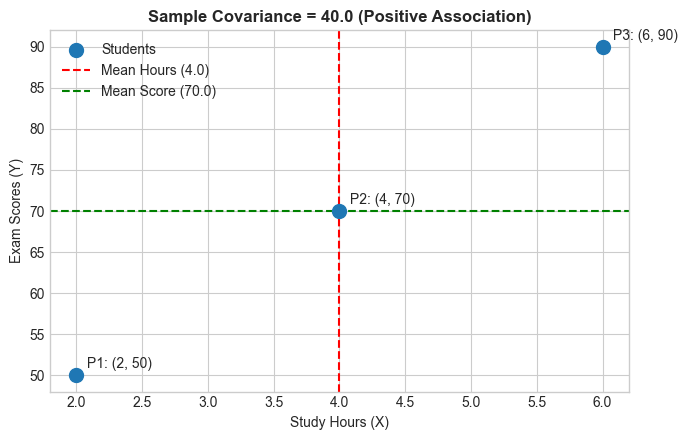

In [5]:
# --- 1. DATA PREPARATION ---
study_hours = np.array([2, 4, 6])
exam_scores = np.array([50, 70, 90])
n = len(study_hours)

# --- 2. PLAIN PYTHON IMPLEMENTATION ---
mean_x = sum(study_hours) / n
mean_y = sum(exam_scores) / n
dev_x = [x - mean_x for x in study_hours]
dev_y = [y - mean_y for y in exam_scores]
prod_dev = [dx * dy for dx, dy in zip(dev_x, dev_y)]
cov_python = sum(prod_dev) / (n - 1)

# --- 3. NUMPY IMPLEMENTATION ---
# rowvar=False treats columns/1D-arrays as variables
cov_matrix_numpy = np.cov(study_hours, exam_scores, rowvar=False, ddof=1) # ddof(delta degrees of freedom)  =1 for sample covariance

cov_numpy = cov_matrix_numpy[0, 1]
'''
np.cov returns the covariance matrix, 
where the diagonal elements are the variances of each variable and 
the off-diagonal elements are the covariances between variables.
cov_matrix: 
[[var(x) cov(x, y)]
 [cov(y, x) var(y)]]
'''

print(f"Plain Python Covariance: {cov_python:.1f}")
print(f"var({study_hours}) study hours var(x): {np.var(study_hours, ddof=1):.1f}")
print(f"var({exam_scores}) exam scores var(y): {np.var(exam_scores, ddof=1):.1f}")
print(f"NumPy Covariance Cov(X, Y): {cov_numpy:.1f}\n")
print(f"NumPy np.cov Matrix:\n{cov_matrix_numpy}")

# --- 4. VISUAL REPRESENTATION ---
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(study_hours, exam_scores, color='#1f77b4', s=100, zorder=5, label='Students')
ax.axvline(mean_x, color='red', linestyle='--', label=f'Mean Hours ({mean_x:.1f})')
ax.axhline(mean_y, color='green', linestyle='--', label=f'Mean Score ({mean_y:.1f})')

for i in range(n):
    ax.annotate(f' P{i+1}: ({study_hours[i]}, {exam_scores[i]})',
                (study_hours[i], exam_scores[i]), textcoords="offset points", xytext=(5,5))

ax.set_xlabel('Study Hours (X)')
ax.set_ylabel('Exam Scores (Y)')
ax.set_title(f'Sample Covariance = {cov_numpy:.1f} (Positive Association)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 2. Pearson Correlation Coefficient (`np.corrcoef`)

* **What it does:** Standardizes covariance by scaling it between $-1$ and $+1$ using the standard deviations of both variables. It isolates the strength and direction of linear relationship.
* **Mathematical Notation:**
  $$r_{xy} = \frac{\operatorname{Cov}(X, Y)}{s_x \cdot s_y} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$
  *Where:*
  * $r_{xy}$ (*r sub x y*): Sample Pearson correlation coefficient
  * $s_x$ (*s sub x*): Sample standard deviation of $X$
  * $s_y$ (*s sub y*): Sample standard deviation of $Y$
* **Naive Example:** Using our previous study data ($X=[2, 4, 6]$, $Y=[50, 70, 90]$):
  * $\operatorname{Cov}(X,Y) = 40.0$
  * $s_x = \sqrt{\frac{8}{2}} = 2.0$
  * $s_y = \sqrt{\frac{800}{2}} = 20.0$
  * Pearson Correlation: $r = \frac{40.0}{2.0 \times 20.0} = \frac{40.0}{40.0} = 1.0$ (Perfect Positive Linear Correlation)
* **When to use:** When assessing direct linear relationships, checking feature collinearity, or finding feature-target correlation scale-independently.

Plain Python Pearson r: 1.0000
NumPy np.corrcoef r:   1.0000
Pandas Series corr r:  1.0000

____________________________________________________________
   Hours  Scores
0      2      50
1      4      70
2      6      90
____________________________________________________________
        count  mean   std   min   25%   50%   75%   max
Hours     3.0   4.0   2.0   2.0   3.0   4.0   5.0   6.0
Scores    3.0  70.0  20.0  50.0  60.0  70.0  80.0  90.0


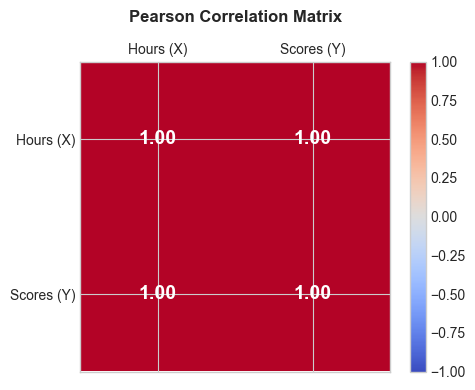

In [7]:
# --- 1. PLAIN PYTHON IMPLEMENTATION ---
var_x = sum((x - mean_x) ** 2 for x in study_hours) / (n - 1)
var_y = sum((y - mean_y) ** 2 for y in exam_scores) / (n - 1)
std_x = math.sqrt(var_x)
std_y = math.sqrt(var_y)

r_python = cov_python / (std_x * std_y)

# --- 2. NUMPY & PANDAS IMPLEMENTATIONS ---
r_numpy_matrix = np.corrcoef(study_hours, exam_scores)
r_numpy = r_numpy_matrix[0, 1]
'''
np.corrcoef returns the Pearson correlation coefficient matrix,
where the diagonal elements are always 1 (correlation of a variable with itself) and
the off-diagonal elements are the Pearson correlation coefficients between variables.
r_numpy_matrix:
[[1        r(x, y)]
 [r(y, x) 1       ]]
'''
df = pd.DataFrame({'Hours': study_hours, 'Scores': exam_scores})
r_pandas = df['Hours'].corr(df['Scores'])

print(f"Plain Python Pearson r: {r_python:.4f}")
print(f"NumPy np.corrcoef r:   {r_numpy:.4f}")
print(f"Pandas Series corr r:  {r_pandas:.4f}\n")
print("_" * 60)
print(df)
print("_" * 60)
print(df.describe().T)


# --- 3. VISUAL HEATMAP REPRESENTATION ---
fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(r_numpy_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{r_numpy_matrix[i, j]:.2f}", ha='center', va='center',
                color='white' if abs(r_numpy_matrix[i, j]) > 0.5 else 'black', fontweight='bold', fontsize=14)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_yticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_title('Pearson Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 3. Directional Patterns & Non-Linear Limitations

Pearson's correlation coefficient ($r$) is one of the most widely used bivariate metrics in data analytics, but it is also one of the most frequently misunderstood and misapplied. To use it reliably in exploratory data analysis (EDA) and feature engineering, two foundational concepts must be mastered:
1. **How Directional Patterns work geometrically** (the four-quadrant cross-product mechanism).
2. **Why Pearson's $r$ is blind to Non-Linear dependencies** (the linearity assumption and symmetrical cancellation traps).

---

#### A. Directional Patterns & The Four-Quadrant Sign Mechanics

The numerator of both sample covariance and Pearson's $r$ is the **Sum of Products of Deviations**:
$$\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$

Geometrically, the point $(\bar{x}, \bar{y})$ forms the **centroid** of the bivariate scatter. Lines $X = \bar{x}$ and $Y = \bar{y}$ divide the scatterplot into four distinct quadrants centered at the means:

| Quadrant | Coordinate Condition | Deviation Signs: $(x_i - \bar{x})$ and $(y_i - \bar{y})$ | Product Sign | Directional Impact |
| :--- | :---: | :---: | :---: | :--- |
| **Quadrant I (Top-Right)** | $X > \bar{x}, \; Y > \bar{y}$ | $(+) \times (+)$ | **Positive (+)** | Both variables above average $\implies$ drives $r > 0$. |
| **Quadrant II (Top-Left)** | $X < \bar{x}, \; Y > \bar{y}$ | $(-) \times (+)$ | **Negative (-)** | $X$ below average, $Y$ above $\implies$ drives $r < 0$. |
| **Quadrant III (Bottom-Left)** | $X < \bar{x}, \; Y < \bar{y}$ | $(-) \times (-)$ | **Positive (+)** | Both variables below average $\implies$ drives $r > 0$. |
| **Quadrant IV (Bottom-Right)** | $X > \bar{x}, \; Y < \bar{y}$ | $(+) \times (-)$ | **Negative (-)** | $X$ above average, $Y$ below $\implies$ drives $r < 0$. |

- **Positive Linear Association ($r > 0$):** Points cluster predominantly in **Quadrants I and III**. The positive cross-products dominate.
- **Negative Linear Association ($r < 0$):** Points cluster predominantly in **Quadrants II and IV**. The negative cross-products dominate.
- **Uncorrelated / Random Cloud ($r \approx 0$):** Points are evenly scattered across all four quadrants; positive and negative cross-products cancel each other out.

> **Covariance vs. Pearson $r$:** While covariance preserves the sign, its magnitude is **scale-dependent** (e.g., converting Study Hours to Study Minutes multiplies covariance by 60). Pearson's $r = \frac{s_{xy}}{s_x s_y}$ normalizes covariance by the standard deviations, yielding a **dimensionless metric** bounded strictly in $[-1.0, +1.0]$.

---

#### B. The 4 Critical Non-Linear Limitations of Pearson's $r$

The fundamental assumption of Pearson's correlation is **LINEARITY** — it measures strictly how well the relationship can be approximated by a single straight line ($Y = \beta_0 + \beta_1 X$). When relationships are non-linear, Pearson's $r$ can produce dangerously misleading conclusions:

##### 1. The Symmetrical Cancellation Trap (Parabolic $Y = X^2$)
- If $Y = X^2$ over a symmetric interval $[-a, a]$, $Y$ is **100% deterministically dependent** on $X$ (zero randomness).
- **Mathematical Proof:**
  $$\operatorname{Cov}(X, X^2) = \mathbb{E}[X \cdot X^2] - \mathbb{E}[X]\mathbb{E}[X^2] = \mathbb{E}[X^3] - \mathbb{E}[X]\mathbb{E}[X^2]$$
  For any symmetric distribution centered at 0, all odd central moments vanish: $\mathbb{E}[X] = 0$ and $\mathbb{E}[X^3] = 0$:
  $$\operatorname{Cov}(X, X^2) = 0 - 0 = 0 \implies r = 0$$
- **Intuitive Hand Proof ($n = 5$):** $X = [-2, -1, 0, 1, 2]$ and $Y = X^2 = [4, 1, 0, 1, 4]$.
  * $\bar{x} = 0, \; \bar{y} = 2$.
  * Deviations $X$: $[-2, -1, 0, +1, +2]$. Deviations $Y$: $[+2, -1, -2, -1, +2]$.
  * Products: $(-2 \times 2) + (-1 \times -1) + (0 \times -2) + (1 \times -1) + (2 \times 2) = -4 + 1 + 0 - 1 + 4 = \mathbf{0.0}$.
  * The downward slope of the left arm ($X < 0$) is exactly cancelled by the upward slope of the right arm ($X > 0$).
- ⚠️ **Critical Exam Takeaway:** **"$r = 0$ does NOT mean independence!"** It only proves the absence of a *linear* trend.

##### 2. The Monotonic Attenuation Trap (Exponential $Y = e^X$, Power $Y = X^3$)
- When $Y$ increases monotonically with $X$, the rank ordering is strictly preserved ($100\%$ order agreement).
- However, because an exponential curve accelerates upward, a straight line cannot fit all points evenly $\implies$ Pearson's $r$ is penalized and attenuated (typically $r \approx 0.85 - 0.90$).
- **Solution:** **Spearman Rank Correlation ($\rho$)** replaces raw values with their integer ranks. Because $\text{Rank}(e^X) = \text{Rank}(X)$, Spearman's $\rho = \mathbf{+1.0000}$ (perfect monotonic correlation).

##### 3. Periodic & Closed-Form Geometry (Sinusoidal $Y = \sin(X)$, Circular $X^2 + Y^2 = R^2$)
- In cyclic or circular structures, observations distribute symmetrically around the centroid $\implies r \approx 0.0$.
- Pearson correlation detects no signal, despite complex deterministic geometric structure.

##### 4. Vulnerability to Outliers & High Leverage (Anscombe's Quartet)
- Pearson's $r$ relies on squared deviations ($s_x, s_y$) and product sums, making it highly sensitive to extreme outliers.
- A single distant leverage point can turn an uncorrelated scatter ($r \approx 0$) into an apparent strong correlation ($r > 0.8$), or vice-versa.

---

#### C. Decision Framework: Choosing the Right Association Metric

| Association Metric | Linearity Assumed? | Monotonicity Assumed? | Scale Invariant? | Resistant to Outliers? | Best Used For |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Covariance ($s_{xy}$)** | Yes | Yes | **No** (Scale-dependent) | No | Initial joint direction; PCA; Portfolio variance matrices. |
| **Pearson Correlation ($r$)** | **Yes** | Yes | **Yes** ($[-1, +1]$) | No | Linear associations in continuous, normally distributed data. |
| **Spearman Rank ($\rho$)** | No | **Yes** | **Yes** ($[-1, +1]$) | **Yes** (Rank-based) | Non-linear monotonic curves ($e^X, \ln X$), ordinal data, or data with outliers. |
| **Mutual Information ($MI$)** | **No** | **No** | Normalized $[0, 1]$ | **Yes** | General non-linear dependencies (parabolas, circles, multi-modal clusters). |

Relationship Pattern             | Pearson (r)        | Spearman (rho)    
1. Positive Linear               | r =  +0.9724 (p=1.8e-95) | rho =  +0.9740 (p=2.6e-97)
2. Negative Linear               | r =  -0.9684 (p=4.2e-91) | rho =  -0.9691 (p=7.4e-92)
3. Uncorrelated Noise            | r =  +0.1232 (p=1.3e-01) | rho =  +0.1122 (p=1.7e-01)
4. Quadratic (Y = X²)            | r =  +0.0087 (p=9.2e-01) | rho =  +0.0060 (p=9.4e-01)
5. Monotonic Exp (Y = eˣ)        | r =  +0.8953 (p=7.9e-54) | rho =  +0.9786 (p=1.7e-103)
6. Periodic Wave (Y = sin X)     | r =  -0.3849 (p=1.2e-06) | rho =  -0.3727 (p=2.6e-06)


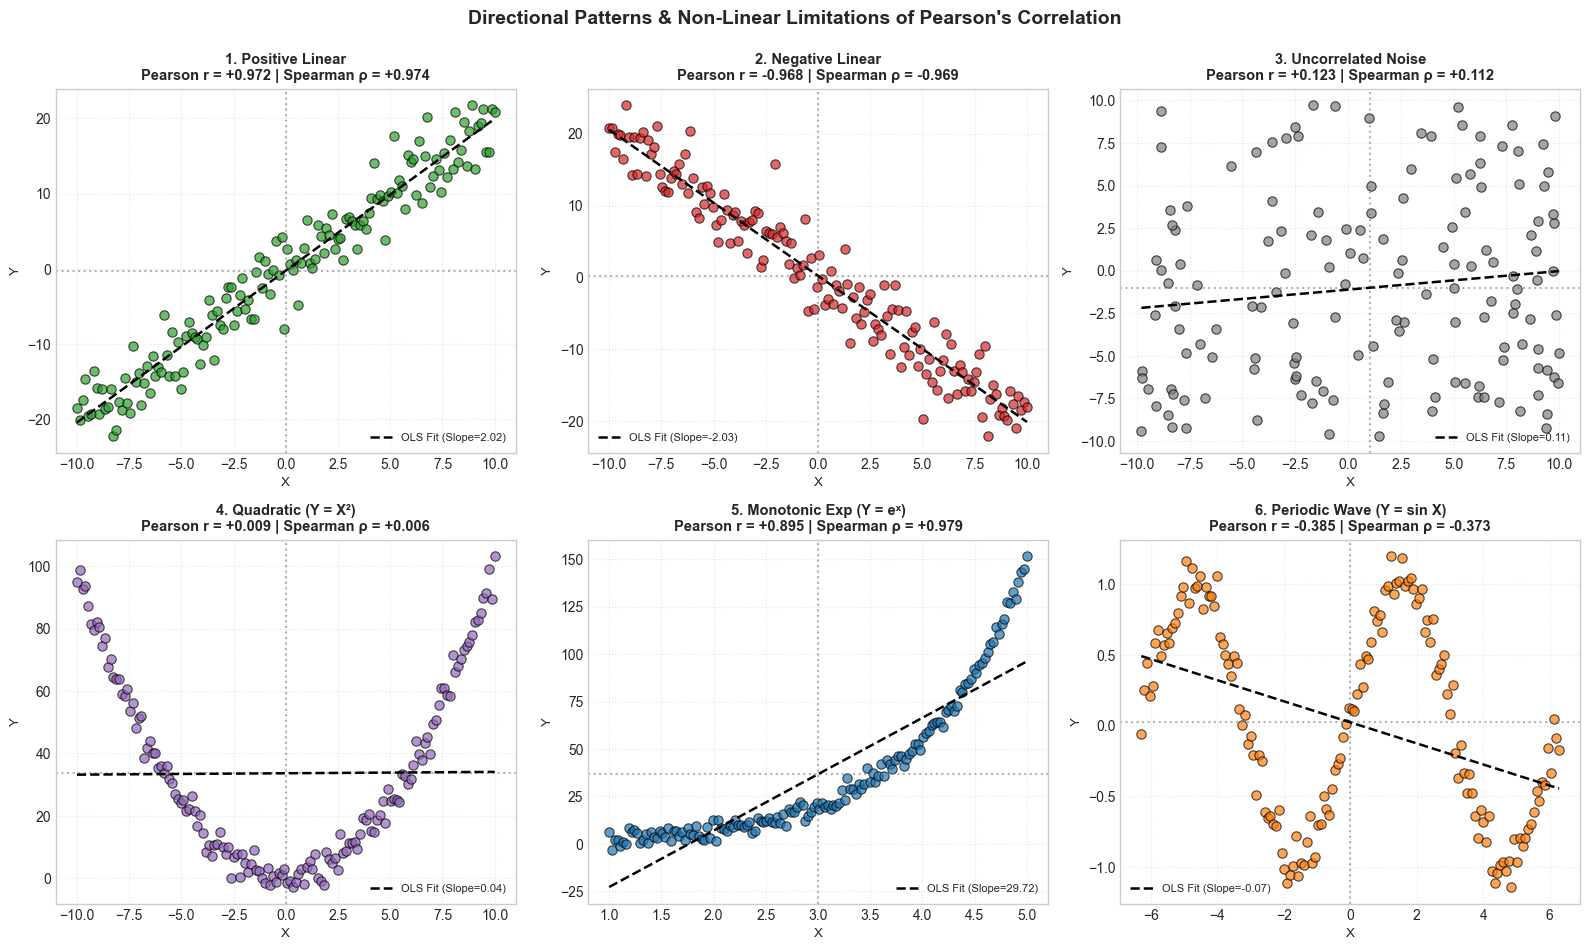

In [9]:
# ==============================================================================
# COMPREHENSIVE BENCHMARK: DIRECTIONAL PATTERNS VS NON-LINEAR LIMITATIONS
# ==============================================================================
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)
n_pts = 150

# 1. Positive Linear (r ≈ +0.97)
x_pos = np.linspace(-10, 10, n_pts)
y_pos = 2.0 * x_pos + np.random.normal(0, 3, n_pts)

# 2. Negative Linear (r ≈ -0.97)
x_neg = np.linspace(-10, 10, n_pts)
y_neg = -2.0 * x_neg + np.random.normal(0, 3, n_pts)

# 3. Uncorrelated Noise (r ≈ 0.00)
x_unc = np.random.uniform(-10, 10, n_pts)
y_unc = np.random.uniform(-10, 10, n_pts)

# 4. Quadratic Parabola (Y = X², r ≈ 0.00 - Perfect Non-Linear Dependency!)
x_quad = np.linspace(-10, 10, n_pts)
y_quad = x_quad**2 + np.random.normal(0, 3, n_pts)

# 5. Monotonic Exponential (Y = exp(X), Pearson r attenuated vs Spearman ρ ≈ 1.0)
x_exp = np.linspace(1, 5, n_pts)
y_exp = np.exp(x_exp) + np.random.normal(0, 3, n_pts)

# 6. Periodic Sinusoidal (Y = sin(X), r ≈ 0.00 - Wave Pattern)
x_sin = np.linspace(-2 * np.pi, 2 * np.pi, n_pts)
y_sin = np.sin(x_sin) + np.random.normal(0, 0.12, n_pts)

patterns = [
    ("1. Positive Linear", x_pos, y_pos, "#2ca02c"),
    ("2. Negative Linear", x_neg, y_neg, "#d62728"),
    ("3. Uncorrelated Noise", x_unc, y_unc, "#7f7f7f"),
    ("4. Quadratic (Y = X²)", x_quad, y_quad, "#9467bd"),
    ("5. Monotonic Exp (Y = eˣ)", x_exp, y_exp, "#1f77b4"),
    ("6. Periodic Wave (Y = sin X)", x_sin, y_sin, "#ff7f0e")
]

# Print Comparative Summary Table
print("=" * 78)
print(f"{'Relationship Pattern':<32} | {'Pearson (r)':<18} | {'Spearman (rho)':<18}")
print("=" * 78)
metrics = []
for title, x_d, y_d, color in patterns:
    r_val, p_r = stats.pearsonr(x_d, y_d)
    rho_val, p_rho = stats.spearmanr(x_d, y_d)
    metrics.append((r_val, rho_val))
    print(f"{title:<32} | r = {r_val:+8.4f} (p={p_r:.1e}) | rho = {rho_val:+8.4f} (p={p_rho:.1e})")
print("=" * 78)

# Multi-Panel Visualization (2 Rows x 3 Columns)
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
axes = axes.flatten()

for i, (title, x_d, y_d, color) in enumerate(patterns):
    ax = axes[i]
    r_val, rho_val = metrics[i]
    ax.scatter(x_d, y_d, color=color, alpha=0.7, edgecolors='k', linewidth=0.8, s=45)
    
    # Draw mean crosshairs to visualize quadrants
    ax.axvline(np.mean(x_d), color='gray', linestyle=':', alpha=0.6)
    ax.axhline(np.mean(y_d), color='gray', linestyle=':', alpha=0.6)
    
    # Add OLS regression fit line
    slope, intercept = np.polyfit(x_d, y_d, 1)
    x_fit = np.linspace(x_d.min(), x_d.max(), 100)
    ax.plot(x_fit, intercept + slope * x_fit, color='black', linestyle='--', linewidth=1.8,
            label=f'OLS Fit (Slope={slope:.2f})')
    
    ax.set_title(f"{title}\nPearson r = {r_val:+.3f} | Spearman ρ = {rho_val:+.3f}",
                 fontweight='bold', fontsize=10.5)
    ax.set_xlabel('X', fontsize=9.5)
    ax.set_ylabel('Y', fontsize=9.5)
    ax.legend(loc='lower right' if slope >= 0 else 'lower left', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Directional Patterns & Non-Linear Limitations of Pearson\'s Correlation', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
